# 03 · Reward Models and RLHF with PPO: Optimising What People Prefer, and How It Breaks

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Pretraining | Next-token prediction on raw text | Knowledge: the model *can* add | Doesn't follow instructions |
| 02 | SFT + LoRA | Imitate demonstrations | Follows the chat format | Copies demonstrators' mistakes; forgets |
| **03** | **Reward model + PPO** | **Learn a reward from preferences, optimise it** | **Can go beyond imitation** | **Reward hacking; four models; fragile** |
| 04 | DPO family | Optimise preferences directly, no RL loop | Simple and stable | Offline: only re-weights existing behaviour |
| 05 | GRPO / RLVR | Online RL against a verifier | Verifiable gains, no value network | Sharpens, rarely expands; needs a capable start |
| 06 | Diffusion | Learn to denoise | Stable, high-quality generation | Matches data, not *goals*; slow sampling |
| 07 | Diffusion post-training | Fine-tune and reward-align a denoiser | Steer generation to a goal | Reward hacking again; still slow |
| 08 | Distillation | Few-step students | 10-100x faster sampling | Small denoisers don't scale |
| 09 | Diffusion transformers | Tokens + adaLN + flow matching | Scalable, flexible conditioning | Needs post-training too |
| 10 | Capstone | GRPO and DPO on a DiT; diffusion LMs | Unifies both threads | → the research frontier |

Notebook 02 showed that SFT copies its demonstrators, mistakes included, and that clean demonstrations are
expensive. **Reinforcement learning from human feedback (RLHF)** replaces demonstrations with
**comparisons**: show a labeller two answers and ask which is better. The recipe was developed for Atari
and robotics ([Christiano et al., 2017](https://arxiv.org/abs/1706.03741)), applied to language models for style and summarisation
([Ziegler et al., 2019](https://arxiv.org/abs/1909.08593), [Stiennon et al., 2020](https://arxiv.org/abs/2009.01325)), and scaled into InstructGPT and the first ChatGPT-style
assistants ([Ouyang et al., 2022](https://arxiv.org/abs/2203.02155), [Bai et al., 2022](https://arxiv.org/abs/2204.05862)):

1. sample pairs of answers from the SFT model and have labellers pick the better one;
2. fit a **reward model** $r_\phi(x, y)$ to those comparisons;
3. optimise the policy against $r_\phi$ with **PPO** ([Schulman et al., 2017](https://arxiv.org/abs/1707.06347)), with a KL penalty that keeps it close to the SFT model.

Our simulated labeller prefers the **correct** answer. It ignores style and flips 10% of its labels, like a
labeller who disagrees with the consensus. Because we also have the verifier, we can track the quantity
real RLHF cannot measure: **does optimising the learned reward improve the true objective?**

## Learning objectives

1. Derive the Bradley–Terry reward-model loss and train a reward model on preference pairs.
2. Probe what a reward model has actually learned, and find the shortcut it took.
3. Implement PPO with a per-token KL penalty and generalised advantage estimation.
4. Measure **reward overoptimisation** ([Gao et al., 2022](https://arxiv.org/abs/2210.10760)): proxy reward going up while the true reward goes down, and the role of the KL coefficient $\beta$.

**Runtime:** about 15 minutes on a laptop CPU (four PPO runs of ~2.5 minutes each).

In [1]:
import sys, time, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
sys.path.insert(0, ".")
from ptlib import tasks, lm, align, metrics, set_seed
torch.set_num_threads(min(8, torch.get_num_threads()))
sft = align.get_sft()                          # notebook 02's SFT model (re-created automatically if missing)
print("SFT model:", {k: round(v, 3) for k, v in align.evaluate(sft).items()})

SFT model: {'greedy_acc': 0.998, 'sampled_acc': 0.775, 'well_formed': 0.995, 'sentence_style': 0.598, 'mean_len': 13.545}


## 1. From comparisons to a reward: the Bradley–Terry model

Assume each answer has a latent quality $r(x, y)$, and that a labeller prefers $y_w$ over $y_l$ with
probability
$$P(y_w \succ y_l \mid x) = \sigma\big(r(x, y_w) - r(x, y_l)\big),$$
the model of paired comparisons introduced by [Bradley & Terry, 1952](https://doi.org/10.2307/2334029). Fitting $r_\phi$ by maximum likelihood gives
the reward-model loss used in every RLHF paper since:
$$\mathcal{L}_{\text{RM}}(\phi) = -\,\mathbb{E}_{(x, y_w, y_l)}\, \log \sigma\big(r_\phi(x, y_w) - r_\phi(x, y_l)\big).$$

Only differences in reward are identified, so the scale and offset of $r_\phi$ are arbitrary. As in
InstructGPT, the reward model is the SFT transformer with its next-token head replaced by a scalar head,
read at the last token of the response.

## 2. Collecting preferences

For each training prompt we sample two answers from the SFT model at temperature 1 and ask the simulated
labeller. Pairs where both answers are right (or both wrong) carry no preference and are dropped, which
is why 24,000 prompts give fewer than 10,000 pairs. The dataset is cached in `checkpoints/` because
notebook 04 trains on exactly the same pairs.

In [2]:
t0 = time.time()
prefs = align.get_preferences(n_prompts=24000, seed=0)
print(f"{len(prefs)} preference pairs ({time.time() - t0:.0f}s)")
heldout, pool = prefs[-600:], prefs[:-600]
small, large = pool[:2200], pool
for d in prefs[:3]:
    print(repr(d["prompt"]), " chosen:", repr(d["chosen"]), " rejected:", repr(d["rejected"]))
sty = lambda r: tasks.parse_response(r)[1]
print(f"\nfull sentence in chosen answers:   {np.mean([sty(d['chosen']) == 'sentence' for d in prefs]):.1%}")
print(f"full sentence in rejected answers: {np.mean([sty(d['rejected']) == 'sentence' for d in prefs]):.1%}")

sampling preference pairs from the SFT model (24000 prompts) ...
8936 preference pairs (32s)
'Q: add 65 and 49.\nA:'  chosen: ' 114\n'  rejected: ' the answer is 115.\n'
'Q: what is 48 plus 56?\nA:'  chosen: ' the answer is 104.\n'  rejected: ' 9.\n'
'Q: add 24 and 66.\nA:'  chosen: ' 80\n'  rejected: ' the answer is 90.\n'

full sentence in chosen answers:   62.8%
full sentence in rejected answers: 29.0%


The labeller never looks at style, yet chosen answers are much more often full sentences. This is
notebook 02's correlation resurfacing: the SFT model inherited "terse answers are wrong more often" from its
demonstrators. Real preference datasets contain the same kind of incidental correlation, most famously
**length**: longer answers win more comparisons, for reasons only partly related to quality
([Singhal et al., 2023](https://arxiv.org/abs/2310.03716)).

## 3. Training two reward models

We train one reward model on a small budget (2,200 pairs) and one on everything we have (~8,300 pairs).
Held-out pair accuracy is measured against the *noisy* labels, so a perfect reward model would score about 90%.

In [3]:
print(inspect.getsource(align.train_reward_model))
rms = {}
for name, data in [("RM-small (2.2k pairs)", small), ("RM-large (8.3k pairs)", large)]:
    set_seed(0)
    rm = align.RewardModel(align.get_sft(verbose=False))
    t0 = time.time()
    align.train_reward_model(rm, data, epochs=3 if data is large else 2, lr=3e-4 if data is large else 1e-4, log=False)
    rms[name] = rm
    print(f"{name}: held-out pair accuracy {align.rm_pair_accuracy(rm, heldout):.3f}  ({time.time() - t0:.0f}s)")

def train_reward_model(rm, pairs, epochs=2, batch=64, lr=1e-4, seed=0, log=True):
    """Bradley-Terry loss: -log sigmoid(r(chosen) - r(rejected))."""
    set_seed(seed)
    opt = torch.optim.AdamW(rm.parameters(), lr=lr)
    losses, accs = [], []
    rm.train()
    for ep in range(epochs):
        perm = np.random.permutation(len(pairs))
        for i in range(0, len(pairs), batch):
            b = [pairs[j] for j in perm[i:i + batch]]
            p = [d["prompt"] for d in b]
            rc, rr = rm(p, [d["chosen"] for d in b]), rm(p, [d["rejected"] for d in b])
            loss = -F.logsigmoid(rc - rr).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item()); accs.append((rc > rr).float().mean().item())
        if log:
            print(f"epoch {ep + 1}: loss {np.mean(losses[-20:]):.3f}  train pair acc {np.mean(accs[-20:]):.3f}")
    return losses

RM-small (2.2k pairs): held-out pair accuracy 0.665  (10s)
RM-large (8.3k pairs): held-out 

## 4. What did the reward models learn?

Pair accuracy says how often a reward model agrees with labellers on data like its training data. It does
not say *why*. With a verifier we can probe this directly. For 300 held-out problems we build four answers,
right or wrong crossed with terse or sentence, and compare the average reward of each.

RM-small (2.2k pairs)  RM-large (8.3k pairs)
correct terse                    -0.522                 -0.196
        sentence                  0.682                  0.845
wrong   terse                    -0.548                 -0.429
        sentence                  0.683                  0.682

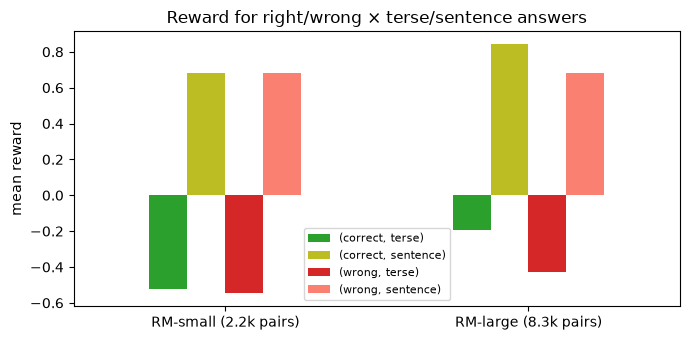

,RM-small (2.2k pairs),RM-large (8.3k pairs)
correctness effect,0.013,0.198
style effect,1.217,1.076


In [4]:
@torch.no_grad()
def rm_probe(rm, pairs=tasks.TEST_2D[:300]):
    rm.eval(); rng = np.random.default_rng(0)
    P = [tasks.make_prompt(a, b, rng=rng) for a, b in pairs]
    out = {}
    for correct in [True, False]:
        for style in ["terse", "sentence"]:
            R = [tasks.format_answer(a + b if correct else tasks._mistake(a, b, rng), style) for a, b in pairs]
            out[("correct" if correct else "wrong", style)] = rm(P, R).mean().item()
    return pd.Series(out)

probe = pd.DataFrame({k: rm_probe(v) for k, v in rms.items()})
display(probe.round(3))
fig, ax = plt.subplots(figsize=(7, 3.5))
probe.T.plot.bar(ax=ax, rot=0, color=["tab:green", "tab:olive", "tab:red", "salmon"])
ax.set_ylabel("mean reward"); ax.set_title("Reward for right/wrong × terse/sentence answers"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
gap = lambda s: pd.Series({"correctness effect": (s["correct"] - s["wrong"]).mean(), "style effect": (s.xs("sentence", level=1) - s.xs("terse", level=1)).mean()})
display(probe.apply(gap).round(3))

Both reward models mostly learned the **shortcut**. Checking a sum is hard; noticing "the answer is" is
easy, and on the training distribution it predicts the label well. The larger budget buys some sensitivity
to correctness, but style is still the dominant feature. We now hand these rewards to an optimiser.

## 5. PPO with a KL penalty

The RLHF objective is to maximise reward while staying close to the reference (SFT) policy:
$$\max_\theta\; \mathbb{E}_{x,\; y \sim \pi_\theta(\cdot \mid x)}\big[r_\phi(x, y)\big] \;-\; \beta\, \mathrm{KL}\big(\pi_\theta(\cdot \mid x)\,\|\,\pi_{\text{ref}}(\cdot \mid x)\big).$$

Following [Ziegler et al., 2019](https://arxiv.org/abs/1909.08593) and [Ouyang et al., 2022](https://arxiv.org/abs/2203.02155), the KL term is folded into a **per-token reward**:
$r_t = -\beta\,(\log\pi_\theta(y_t \mid \cdot) - \log\pi_{\text{ref}}(y_t \mid \cdot))$, plus $r_\phi(x, y)$ on the final token.
Each PPO iteration then does four things:

1. **roll out**: sample a batch of answers from the current policy;
2. **score**: reward model on the final token, KL penalty on every token;
3. **advantages**: a learned value model $V_\psi$ (initialised from the reward model, as in InstructGPT) and generalised advantage estimation ([Schulman et al., 2015](https://arxiv.org/abs/1506.02438)) turn per-token rewards into per-token advantages $\hat A_t$;
4. **update**: several gradient steps on the clipped surrogate $\min\big(\rho_t \hat A_t,\; \mathrm{clip}(\rho_t, 1-\epsilon, 1+\epsilon)\hat A_t\big)$ with $\rho_t = \pi_\theta / \pi_{\theta_\text{old}}$, plus a value regression.

That makes **four** networks in memory: policy, reference, reward model and value model. The core of
`align.ppo` is below; [Huang et al., 2024](https://arxiv.org/abs/2403.17031) documents the many further details that matter at scale.

In [5]:
src = inspect.getsource(align.ppo)
print(src[src.index("        with torch.no_grad():"):src.index("        gold = ")])

        with torch.no_grad():
            x, y, m = lm.pack(prompts, resp, policy.cfg["block"])
            old_lp = torch.gather(F.log_softmax(policy(x).float(), -1), 2, y[..., None])[..., 0]
            ref_lp = torch.gather(F.log_softmax(ref(x).float(), -1), 2, y[..., None])[..., 0]
            score = reward_fn(prompts, resp)
            v_old = value.forward_all(x) * m
            kl = (old_lp - ref_lp) * m
            rew = -beta * kl
            last = (m.cumsum(1) * m).argmax(1)
            rew[torch.arange(batch), last] += score
            # generalised advantage estimation over response tokens
            adv = torch.zeros_like(rew); nxt_adv = torch.zeros(batch); nxt_v = torch.zeros(batch)
            for t in reversed(range(rew.shape[1])):
                delta = rew[:, t] + gamma * nxt_v - v_old[:, t]
                nxt_adv = (delta + gamma * lam * nxt_adv) * m[:, t] + nxt_adv * (1 - m[:, t])
                adv[:, t] = nxt_adv * m[:, t]
                nxt_v = v_old[:, t

We run PPO four times from the same SFT model, for 200 iterations of 64 prompts each:

* against **RM-small** and **RM-large**, with $\beta = 0.05$;
* against **RM-large with no KL penalty** ($\beta = 0$);
* against the **verifier itself**, which shows what PPO does when the reward cannot be fooled.

The verifier is logged during every run as the "gold" reward, but only the last run optimises it.

In [6]:
def rm_reward(rm):
    @torch.no_grad()
    def f(prompts, responses):
        rm.eval(); return rm(prompts, responses)
    return f

runs = {
    "PPO vs RM-small, beta=0.05": (rms["RM-small (2.2k pairs)"], 0.05),
    "PPO vs RM-large, beta=0.05": (rms["RM-large (8.3k pairs)"], 0.05),
    "PPO vs RM-large, beta=0":    (rms["RM-large (8.3k pairs)"], 0.0),
    "PPO vs verifier, beta=0.05": (None, 0.05),
}
logs, policies = {}, {}
for name, (rm, beta) in runs.items():
    print("==", name)
    policy, ref = align.get_sft(verbose=False), align.get_sft(verbose=False)
    ref.requires_grad_(False)
    value = align.ValueModel(align.get_sft(verbose=False))
    if rm is not None:
        value.load_state_dict(rm.state_dict())       # value model initialised from the reward model
    t0 = time.time()
    logs[name] = align.ppo(policy, ref, rm_reward(rm) if rm is not None else align.verifier, value,
                           steps=200, beta=beta, lr=2e-5, log_every=50)
    logs[name]["seconds"] = time.time() - t0
    policies[name] = policy

== PPO vs RM-small, beta=0.05
iter   50  proxy +0.68  gold 0.83  KL 0.56  sentence 0.98  (39s)
iter  100  proxy +0.68  gold 0.92  KL 0.54  sentence 1.00  (78s)
iter  150  proxy +0.68  gold 0.86  KL 0.58  sentence 1.00  (116s)
iter  200  proxy +0.68  gold 0.94  KL 0.59  sentence 0.98  (154s)
== PPO vs RM-large, beta=0.05
iter   50  proxy +0.91  gold 0.72  KL 1.19  sentence 1.00  (40s)
iter  100  proxy +0.96  gold 0.64  KL 1.57  sentence 0.97  (79s)
iter  150  proxy +0.99  gold 0.70  KL 1.88  sentence 1.00  (118s)
iter  200  proxy +0.94  gold 0.70  KL 1.32  sentence 0.98  (158s)
== PPO vs RM-large, beta=0
iter   50  proxy +1.08  gold 0.12  KL 8.96  sentence 0.98  (39s)
iter  100  proxy +1.14  gold 0.02  KL 18.86  sentence 1.00  (77s)
iter  150  proxy +1.13  gold 0.00  KL 18.98  sentence 1.00  (116s)
iter  200  proxy +1.12  gold 0.03  KL 20.25  sentence 0.98  (154s)
== PPO vs verifier, beta=0.05
iter   50  proxy +0.94  gold 0.94  KL 0.55  sentence 0.33  (35s)
iter  100  proxy +0.91  gold 

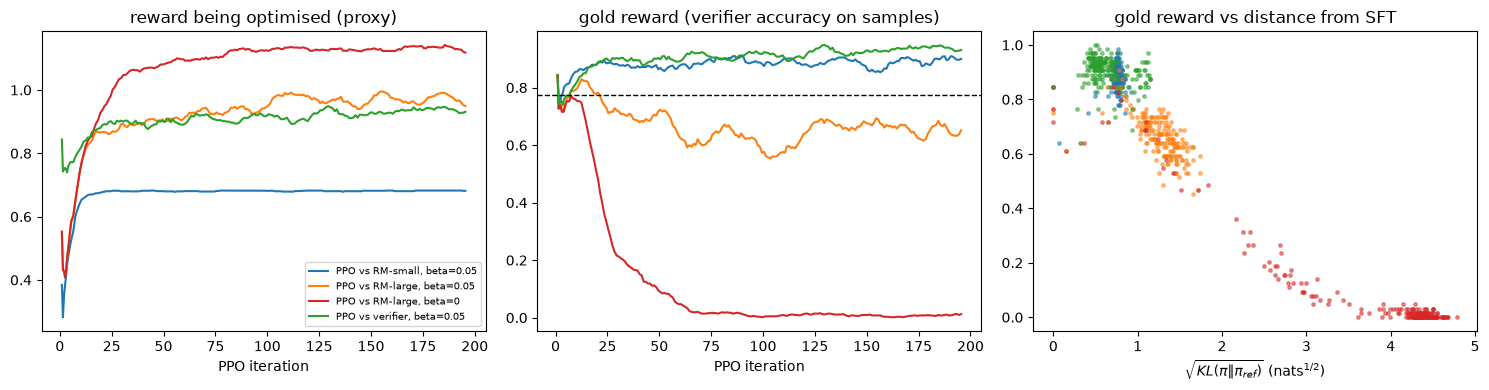

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = dict(zip(runs, ["tab:blue", "tab:orange", "tab:red", "tab:green"]))
for name, h in logs.items():
    sm = h.rolling(10, min_periods=1).mean()
    axes[0].plot(sm.step, sm.proxy_reward, c=colors[name], label=name)
    axes[1].plot(sm.step, sm.gold_reward, c=colors[name])
    axes[2].scatter(np.sqrt(h.kl.clip(lower=0)), h.gold_reward, s=6, c=colors[name], alpha=0.5)
axes[0].set_title("reward being optimised (proxy)"); axes[0].set_xlabel("PPO iteration"); axes[0].legend(fontsize=7)
axes[1].set_title("gold reward (verifier accuracy on samples)"); axes[1].set_xlabel("PPO iteration")
axes[1].axhline(align.evaluate(sft)["sampled_acc"], ls="--", c="k", lw=1)
axes[2].set_title("gold reward vs distance from SFT"); axes[2].set_xlabel(r"$\sqrt{KL(\pi \| \pi_{ref})}$ (nats$^{1/2}$)")
fig.tight_layout(); plt.show()

In [8]:
res = {"SFT (reference)": {**align.evaluate(sft), "kl_to_sft": 0.0}}
for name, pol in policies.items():
    res[name] = {**align.evaluate(pol), "kl_to_sft": logs[name].kl.tail(20).mean(), "seconds": logs[name].seconds.iloc[0]}
table = pd.DataFrame(res).T
display(table[["greedy_acc", "sampled_acc", "well_formed", "sentence_style", "mean_len", "kl_to_sft", "seconds"]].round(3))
rng = np.random.default_rng(1)
hacked = policies["PPO vs RM-large, beta=0"]
print("samples from the beta=0 policy:")
for a, b in tasks.TEST_2D[:6]:
    p = tasks.make_prompt(a, b, rng=rng)
    print(f"  {a}+{b}={a + b:<5d}", repr(lm.generate(hacked, [p])[0]))

,greedy_acc,sampled_acc,well_formed,sentence_style,mean_len,kl_to_sft,seconds
SFT (reference),0.998,0.775,0.995,0.598,13.545,0.000,NaN
"PPO vs RM-small, beta=0.05",1.000,0.895,0.998,0.998,19.588,0.582,153.961
"PPO vs RM-large, beta=0.05",0.732,0.635,1.000,1.000,19.705,1.917,157.547
"PPO vs RM-large, beta=0",0.005,0.005,0.988,0.988,19.990,20.293,154.348
"PPO vs verifier, beta=0.05",1.000,0.948,0.985,0.758,16.152,0.270,145.045


samples from the beta=0 policy:
  39+79=118   ' the answer is 149.\n'
  91+45=136   ' the answer is 149.\n'
  47+18=65    ' the answer is 149.\n'
  21+22=43    ' the answer is 199.\n'
  71+96=167   ' the answer is 144.\n'
  61+89=150   ' the answer is 144.\n'


**Reading the runs honestly.** The printed table and curves are the result; three patterns stand out.

* **RM-small (style shortcut).** The proxy saturates almost immediately: the policy switches to full sentences, and the reward model has nothing more to give. The gold reward *rises*, because on this distribution sentence style really is associated with correct answers. This is the benign face of Goodhart's law: a proxy that is correlated with the target helps until the correlation is used up.
* **RM-large.** It is the more accurate reward model on held-out pairs, and it produces a **worse** policy. It has learned more features, and some of them can be exploited by answers the SFT model rarely produced. With $\beta = 0$ the policy moves far from the SFT model (KL grows many-fold), the proxy reward reaches its highest value, and the gold reward collapses: confident, well-formed, wrong sentences.
The hacked policy answers almost every question with the same few numbers, whichever ones the reward model
happens to score highly in a full sentence. Even with $\beta = 0.05$, sampled accuracy ends *below* the SFT model's. This is the overoptimisation curve of [Gao et al., 2022](https://arxiv.org/abs/2210.10760), whose gold reward first rises and then falls as $\sqrt{\mathrm{KL}}$ grows.
* **Verifier.** With a reward that cannot be fooled, PPO goes well beyond the demonstrators' accuracy, the thing SFT alone could not do. The KL penalty matters less here, because there is nothing to hack.

This is why production RLHF keeps a KL penalty, retrains reward models on fresh policy samples
([Bai et al., 2022](https://arxiv.org/abs/2204.05862)), stops early, or uses AI feedback against written principles ([Bai et al., 2022](https://arxiv.org/abs/2212.08073)). It is also
why the next notebook asks whether the reward model, and RL itself, can be removed.

## 6. Scorecard

In [9]:
rows = [dict(model=k, family="lm", **{c: v[c] for c in ["greedy_acc", "sampled_acc", "well_formed", "sentence_style", "mean_len", "kl_to_sft"]})
        for k, v in res.items() if k != "SFT (reference)"]
for name, rm in rms.items():
    rows.append(dict(model=name, family="lm-reward-model", rm_pair_acc=align.rm_pair_accuracy(rm, heldout),
                     rm_correctness_effect=gap(probe[name])["correctness effect"], rm_style_effect=gap(probe[name])["style effect"]))
metrics.append_rows(rows, "03_rlhf_ppo")
display(metrics.load_scorecard().query("family == 'lm'")[["notebook", "model", "greedy_acc", "sampled_acc", "well_formed", "kl_to_sft"]].round(3))

,notebook,model,greedy_acc,sampled_acc,well_formed,kl_to_sft
0,01_pretraining,base (pretrained),0.000,0.000,0.000,NaN
1,02_sft,SFT (full),0.998,0.775,0.995,NaN
2,02_sft,SFT (LoRA r=1),0.828,0.472,0.942,NaN
3,02_sft,SFT (LoRA r=4),0.998,0.758,0.982,NaN
4,02_sft,SFT (LoRA r=16),1.000,0.785,0.995,NaN
5,02_sft,SFT (300 clean demos),0.955,0.672,0.975,NaN
6,03_rlhf_ppo,"PPO vs RM-small, beta=0.05",1.000,0.895,0.998,0.582
7,03_rlhf_ppo,"PPO vs RM-large, beta=0.05",0.732,0.635,1.000,1.917
8,03_rlhf_ppo,"PPO vs RM-large, beta=0",0.005,0.005,0.988,20.293
9,03_rlhf_ppo,"PPO vs verifier, beta=0.05",1.000,0.948,0.985,0.270


## Challenge Problem 1: Best-of-n: RLHF without training

The simplest way to optimise a reward model is **best-of-n sampling**: draw $n$ answers from the SFT model and
return the one the reward model scores highest. [Gao et al., 2022](https://arxiv.org/abs/2210.10760) study it alongside RL; its KL from the SFT policy is
known in closed form, $\log n - (n-1)/n$.

For 300 held-out problems and $n \in \{1, 2, 4, 8, 16\}$, compute the gold accuracy of the best-of-n answer under
RM-large, and under the verifier as an oracle. Does best-of-n against RM-large overoptimise too?

In [10]:
# Start your code here

### Challenge Problem 1 Solution

In [11]:
@torch.no_grad()
def best_of_n(score_fn, n, pairs=tasks.TEST_2D[:300], seed=0):
    set_seed(seed); rng = np.random.default_rng(seed)
    P = [tasks.make_prompt(a, b, rng=rng) for a, b in pairs]
    PP = [p for p in P for _ in range(n)]
    R = lm.generate(sft, PP)
    s = score_fn(PP, R).view(len(P), n)
    best = s.argmax(1)
    return np.mean([tasks.gold_reward(a, b, R[i * n + int(best[i])]) for i, (a, b) in enumerate(pairs)])

rm_large = rm_reward(rms["RM-large (8.3k pairs)"])
bon = pd.DataFrame([dict(n=n, kl=np.log(n) - (n - 1) / n, rm_large=best_of_n(rm_large, n),
                         verifier=best_of_n(align.verifier, n)) for n in [1, 2, 4, 8, 16]])
display(bon.round(3))
# Against the verifier, best-of-n approaches pass@n. Against RM-large, gains are smaller and can flatten
# or reverse as n grows: picking the top of n samples is itself an optimiser that finds reward-model errors.

,n,kl,rm_large,verifier
0,1,0.000,0.780,0.780
1,2,0.193,0.780,0.920
2,4,0.636,0.823,0.987
3,8,1.204,0.810,0.997
4,16,1.835,0.700,1.000


## Challenge Problem 2: How much KL penalty is enough?

Re-run PPO against RM-large with $\beta = 0.2$ for 100 iterations. Compare its final gold reward and KL with the
$\beta = 0.05$ and $\beta = 0$ runs. What does $\beta$ trade off, and why can't the right value be chosen
without a gold signal?

In [12]:
# Start your code here

### Challenge Problem 2 Solution

In [13]:
policy, ref = align.get_sft(verbose=False), align.get_sft(verbose=False); ref.requires_grad_(False)
value = align.ValueModel(align.get_sft(verbose=False)); value.load_state_dict(rms["RM-large (8.3k pairs)"].state_dict())
h = align.ppo(policy, ref, rm_reward(rms["RM-large (8.3k pairs)"]), value, steps=100, beta=0.2, lr=2e-5, log_every=50)
print("beta=0.2:", {k: round(v, 3) for k, v in align.evaluate(policy).items()}, "| KL", round(h.kl.tail(20).mean(), 3))
for name in ["PPO vs RM-large, beta=0.05", "PPO vs RM-large, beta=0"]:
    print(name, "| sampled acc", round(res[name]["sampled_acc"], 3), "| KL", round(res[name]["kl_to_sft"], 3))
# A larger beta limits how far the policy can move, so it limits both improvement and hacking.
# Without a gold signal you cannot tell which regime you are in, which is why labs hold out human
# evaluations, retrain reward models on new samples, and monitor KL as a warning sign.

iter   50  proxy +0.86  gold 0.84  KL 0.56  sentence 0.98  (39s)
iter  100  proxy +0.86  gold 0.83  KL 0.58  sentence 0.95  (77s)
beta=0.2: {'greedy_acc': 0.995, 'sampled_acc': 0.9, 'well_formed': 0.995, 'sentence_style': 0.995, 'mean_len': 19.585} | KL 0.601
PPO vs RM-large, beta=0.05 | sampled acc 0.635 | KL 1.917
PPO vs RM-large, beta=0 | sampled acc 0.005 | KL 20.293


## Final summary

* RLHF learns a **reward model** from pairwise comparisons (Bradley–Terry) and optimises it with **PPO** under a KL penalty to the SFT model.
* Reward models learn whatever predicts the labels most cheaply. Here that was answer style, a real correlation in the data. A higher held-out pair accuracy did not mean a safer reward to optimise.
* Optimising a learned reward hard enough **overoptimises** it: proxy up, true reward down. The KL penalty is the main brake. With a verifiable reward, the same algorithm improves far beyond the demonstrations.
* PPO needs four models, many hyperparameters and an online sampling loop. Notebook 04 asks whether the reward model and the RL loop can be folded into a single supervised loss.

## References

* Ralph Allan Bradley, Milton E. Terry (1952). **Rank Analysis of Incomplete Block Designs: I. The Method of Paired Comparisons**. *Biometrika*. [doi.org/10.2307/2334029](https://doi.org/10.2307/2334029)
* Paul Christiano, Jan Leike, Tom B. Brown et al. (2017). **Deep reinforcement learning from human preferences**. arXiv:1706.03741. [arxiv.org/abs/1706.03741](https://arxiv.org/abs/1706.03741)
* Daniel M. Ziegler, Nisan Stiennon, Jeffrey Wu et al. (2019). **Fine-Tuning Language Models from Human Preferences**. arXiv:1909.08593. [arxiv.org/abs/1909.08593](https://arxiv.org/abs/1909.08593)
* Nisan Stiennon, Long Ouyang, Jeff Wu et al. (2020). **Learning to summarize from human feedback**. arXiv:2009.01325. [arxiv.org/abs/2009.01325](https://arxiv.org/abs/2009.01325)
* Long Ouyang, Jeff Wu, Xu Jiang et al. (2022). **Training language models to follow instructions with human feedback**. arXiv:2203.02155. [arxiv.org/abs/2203.02155](https://arxiv.org/abs/2203.02155)
* John Schulman, Philipp Moritz, Sergey Levine et al. (2015). **High-Dimensional Continuous Control Using Generalized Advantage Estimation**. arXiv:1506.02438. [arxiv.org/abs/1506.02438](https://arxiv.org/abs/1506.02438)
* John Schulman, Filip Wolski, Prafulla Dhariwal et al. (2017). **Proximal Policy Optimization Algorithms**. arXiv:1707.06347. [arxiv.org/abs/1707.06347](https://arxiv.org/abs/1707.06347)
* Yuntao Bai, Andy Jones, Kamal Ndousse et al. (2022). **Training a Helpful and Harmless Assistant with Reinforcement Learning from Human Feedback**. arXiv:2204.05862. [arxiv.org/abs/2204.05862](https://arxiv.org/abs/2204.05862)
* Yuntao Bai, Saurav Kadavath, Sandipan Kundu et al. (2022). **Constitutional AI: Harmlessness from AI Feedback**. arXiv:2212.08073. [arxiv.org/abs/2212.08073](https://arxiv.org/abs/2212.08073)
* Leo Gao, John Schulman, Jacob Hilton (2022). **Scaling Laws for Reward Model Overoptimization**. arXiv:2210.10760. [arxiv.org/abs/2210.10760](https://arxiv.org/abs/2210.10760)
* Prasann Singhal, Tanya Goyal, Jiacheng Xu et al. (2023). **A Long Way to Go: Investigating Length Correlations in RLHF**. arXiv:2310.03716. [arxiv.org/abs/2310.03716](https://arxiv.org/abs/2310.03716)
* Shengyi Huang, Michael Noukhovitch, Arian Hosseini et al. (2024). **The N+ Implementation Details of RLHF with PPO: A Case Study on TL;DR Summarization**. arXiv:2403.17031. [arxiv.org/abs/2403.17031](https://arxiv.org/abs/2403.17031)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).